# Beehive Sensor Data Preparation

This notebook loads raw sensor readings from a beehive monitoring station (flow, humidity, temperature, weight), inspects them for data-quality issues, and cleans them up for storage in a curated ("silver") layer.

For each sensor we:
- check timestamp regularity and remove duplicates,
- fix timezone handling (readings are stored in local time, which needs to be normalized to UTC because of the twice-yearly clock change), and
- look for suspicious or invalid values (negatives, outliers, missing data).

## Setup
Import the libraries needed for the analysis.

In [2]:
import pandas as pd

In [3]:
# flow = pd.read_csv('flow_schwartau.csv') if the csv file is in the same folder as the notebook

## Loading the raw data
Read each of the four CSV files (flow, humidity, temperature, weight) into its own DataFrame, parsing the `timestamp` column as a datetime on the way in.

In [4]:
path = 'C:/Users/shiva/WBS/case08_Azure/resource/bronze/new/'
flow = pd.read_csv(path+'flow_schwartau.csv', parse_dates=['timestamp'])
humidity = pd.read_csv(path+'humidity_schwartau.csv', parse_dates=['timestamp'])
temperature = pd.read_csv(path+'temperature_schwartau.csv', parse_dates=['timestamp'])
weight = pd.read_csv(path+'weight_schwartau.csv', parse_dates=['timestamp'])

In [5]:
flow

,timestamp,flow
0,2017-01-01 14:15:00,0
1,2017-01-01 14:16:00,0
2,2017-01-01 14:17:00,0
3,2017-01-01 14:18:00,0
4,2017-01-01 14:19:00,0
...,...,...
2513831,2019-05-31 14:11:00,128
2513832,2019-05-31 14:12:00,140
2513833,2019-05-31 14:13:00,144
2513834,2019-05-31 14:14:00,146


## Initial inspection
Check each dataset's structure (column dtypes, non-null counts) before doing any cleaning. In particular, `timestamp` is currently a plain object/string and will need converting to a proper (timezone-aware) datetime type.

In [6]:
flow.info()

<class 'pandas.DataFrame'>
RangeIndex: 2513836 entries, 0 to 2513835
Data columns (total 2 columns):
 #   Column     Dtype         
---  ------     -----         
 0   timestamp  datetime64[us]
 1   flow       int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 38.4 MB


In [7]:
flow.info(show_counts=True) #transform timestamp Dtype

<class 'pandas.DataFrame'>
RangeIndex: 2513836 entries, 0 to 2513835
Data columns (total 2 columns):
 #   Column     Non-Null Count    Dtype         
---  ------     --------------    -----         
 0   timestamp  2513836 non-null  datetime64[us]
 1   flow       2513836 non-null  int64         
dtypes: datetime64[us](1), int64(1)
memory usage: 38.4 MB


In [8]:
flow.isna().sum()

timestamp    0
flow         0
dtype: int64

In [9]:
flow.info?

Signature:
flow.info(
    verbose: 'bool | None' = None,
    buf: 'WriteBuffer[str] | None' = None,
    max_cols: 'int | None' = None,
    memory_usage: 'bool | str | None' = None,
    show_counts: 'bool | None' = None,
) -> 'None'
Docstring:
Print a concise summary of a DataFrame.

This method prints information about a DataFrame including
the index dtype and columns, non-NA values and memory usage.

Parameters
----------
verbose : bool, optional
    Whether to print the full summary. By default, the setting in
    ``pandas.options.display.max_info_columns`` is followed.
buf : writable buffer, defaults to sys.stdout
    Where to send the output. By default, the output is printed to
    sys.stdout. Pass a writable buffer if you need to further process
    the output.
max_cols : int, optional
    When to switch from the verbose to the truncated output. If the
    DataFrame has more than `max_cols` columns, the truncated output
    is used. By default, the setting in
    ``pandas.options

In [10]:
humidity.info() #transform timestamp Dtype

<class 'pandas.DataFrame'>
RangeIndex: 1761 entries, 0 to 1760
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  1761 non-null   datetime64[us]
 1   humidity   1749 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 27.6 KB


In [11]:
temperature.info() #transform timestamp Dtype

<class 'pandas.DataFrame'>
RangeIndex: 253430 entries, 0 to 253429
Data columns (total 2 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   timestamp    253430 non-null  datetime64[us]
 1   temperature  251398 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 3.9 MB


In [12]:
weight.info() #transform timestamp Dtype


<class 'pandas.DataFrame'>
RangeIndex: 1761 entries, 0 to 1760
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  1761 non-null   datetime64[us]
 1   weight     1749 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 27.6 KB


# Flow

### First look at the data
Preview the first and last rows, plus summary statistics, to get a feel for the `flow` values and confirm the roughly 1-minute sampling interval.

In [13]:
flow.head(10) # Looks like the data is arranged by timestamp, every 1 minute

,timestamp,flow
0,2017-01-01 14:15:00,0
1,2017-01-01 14:16:00,0
2,2017-01-01 14:17:00,0
3,2017-01-01 14:18:00,0
4,2017-01-01 14:19:00,0
5,2017-01-01 14:20:00,0
6,2017-01-01 14:21:00,0
7,2017-01-01 14:22:00,0
8,2017-01-01 14:23:00,0
9,2017-01-01 14:24:00,0


In [14]:
flow.tail(10)

,timestamp,flow
2513826,2019-05-31 14:06:00,161
2513827,2019-05-31 14:07:00,169
2513828,2019-05-31 14:08:00,121
2513829,2019-05-31 14:09:00,139
2513830,2019-05-31 14:10:00,149
2513831,2019-05-31 14:11:00,128
2513832,2019-05-31 14:12:00,140
2513833,2019-05-31 14:13:00,144
2513834,2019-05-31 14:14:00,146
2513835,2019-05-31 14:15:00,164


In [15]:
flow.flow.value_counts() # Looks like there are some negative values, which is not possible for flow. We will have to clean this data.

flow
 0       1433363
-1         39998
 1         32574
-2         20405
 2         19710
          ...   
 3148          1
 890           1
 487           1
 656           1
 840           1
Name: count, Length: 950, dtype: int64

In [16]:
flow.describe()

,timestamp,flow
count,2513836,2.513836e+06
mean,2018-03-18 15:57:52.410674,1.624583e+00
min,2017-01-01 14:15:00,-6.310000e+02
25%,2017-08-13 06:00:00,0.000000e+00
50%,2018-03-19 10:16:30,0.000000e+00
75%,2018-10-24 07:27:00,0.000000e+00
max,2019-05-31 14:15:00,7.999000e+03
std,NaN,5.432563e+01


### Checking for duplicate timestamps
Count how often flow is exactly 0, then check for duplicate rows and see whether sorting by timestamp reveals anything about how the data is arranged.

In [17]:
# how often is the flow 0
flow['flow'].value_counts()

flow
 0       1433363
-1         39998
 1         32574
-2         20405
 2         19710
          ...   
 3148          1
 890           1
 487           1
 656           1
 840           1
Name: count, Length: 950, dtype: int64

In [18]:
flow.duplicated().sum()

np.int64(697348)

In [19]:
flow.sort_values(by='timestamp').head(30)

,timestamp,flow
0,2017-01-01 14:15:00,0
1256918,2017-01-01 14:15:00,0
1256919,2017-01-01 14:16:00,0
1,2017-01-01 14:16:00,0
2,2017-01-01 14:17:00,0
1256920,2017-01-01 14:17:00,0
3,2017-01-01 14:18:00,0
1256921,2017-01-01 14:18:00,0
4,2017-01-01 14:19:00,0
1256922,2017-01-01 14:19:00,0


<Axes: title={'center': 'Flow distribution'}, ylabel='Frequency'>

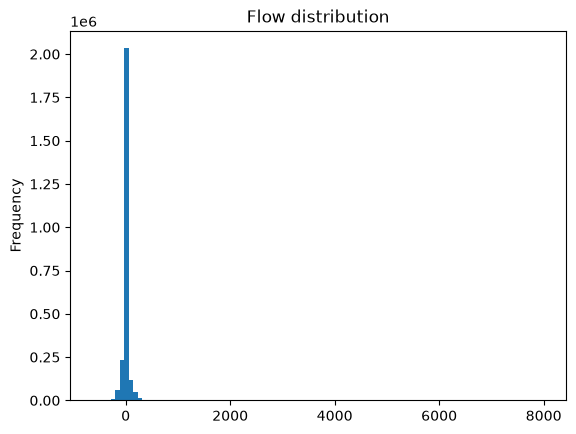

In [20]:
flow.flow.plot(kind='hist', bins=100, title='Flow distribution')

In [21]:
flow.flow.value_counts()
flow['flow'].value_counts(normalize=True)*100

flow
 0       57.018954
-1        1.591114
 1        1.295789
-2        0.811708
 2        0.784061
           ...    
 3148     0.000040
 890      0.000040
 487      0.000040
 656      0.000040
 840      0.000040
Name: proportion, Length: 950, dtype: float64

In [22]:
flow.describe()

,timestamp,flow
count,2513836,2.513836e+06
mean,2018-03-18 15:57:52.410674,1.624583e+00
min,2017-01-01 14:15:00,-6.310000e+02
25%,2017-08-13 06:00:00,0.000000e+00
50%,2018-03-19 10:16:30,0.000000e+00
75%,2018-10-24 07:27:00,0.000000e+00
max,2019-05-31 14:15:00,7.999000e+03
std,NaN,5.432563e+01


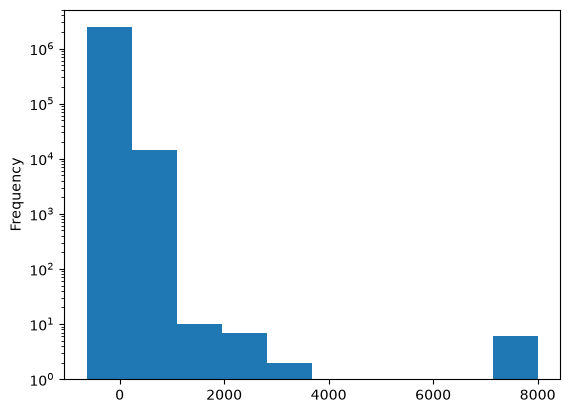

In [23]:
import matplotlib.pyplot as plt
flow.flow.plot(kind='hist')
plt.yscale('log')

### Splitting the two directions of flow
The row count is used to find the file's midpoint. The data looks like all readings in one direction followed by all readings in the other direction, so the midpoint is used to split the flow data into `departures` and `arrivals`.

In [24]:
flow.shape[0]

2513836

In [25]:
flow.shape[0]//2

1256918

`/` always returns `float`     
`//` always returns `int`

In [26]:
flow.iloc[:flow.shape[0]//2]
#timstamp still covers all dates
#maybe the flow is all non-positives

,timestamp,flow
0,2017-01-01 14:15:00,0
1,2017-01-01 14:16:00,0
2,2017-01-01 14:17:00,0
3,2017-01-01 14:18:00,0
4,2017-01-01 14:19:00,0
...,...,...
1256913,2019-05-31 14:11:00,-241
1256914,2019-05-31 14:12:00,-226
1256915,2019-05-31 14:13:00,-208
1256916,2019-05-31 14:14:00,-217


In [27]:
flow.iloc[flow.shape[0]//2:]

#timstamp still covers all dates
#maybe the flow is all non-negative

,timestamp,flow
1256918,2017-01-01 14:15:00,0
1256919,2017-01-01 14:16:00,0
1256920,2017-01-01 14:17:00,0
1256921,2017-01-01 14:18:00,0
1256922,2017-01-01 14:19:00,0
...,...,...
2513831,2019-05-31 14:11:00,128
2513832,2019-05-31 14:12:00,140
2513833,2019-05-31 14:13:00,144
2513834,2019-05-31 14:14:00,146


In [28]:
flow.sort_values(by='timestamp').head(30)

,timestamp,flow
0,2017-01-01 14:15:00,0
1256918,2017-01-01 14:15:00,0
1256919,2017-01-01 14:16:00,0
1,2017-01-01 14:16:00,0
2,2017-01-01 14:17:00,0
1256920,2017-01-01 14:17:00,0
3,2017-01-01 14:18:00,0
1256921,2017-01-01 14:18:00,0
4,2017-01-01 14:19:00,0
1256922,2017-01-01 14:19:00,0


In [29]:
flow.sort_values(by='timestamp').tail(30)

,timestamp,flow
2513821,2019-05-31 14:01:00,170
1256903,2019-05-31 14:01:00,-172
1256904,2019-05-31 14:02:00,-219
2513822,2019-05-31 14:02:00,174
2513823,2019-05-31 14:03:00,148
1256905,2019-05-31 14:03:00,-229
2513824,2019-05-31 14:04:00,161
1256906,2019-05-31 14:04:00,-228
2513825,2019-05-31 14:05:00,164
1256907,2019-05-31 14:05:00,-203


<Axes: ylabel='Frequency'>

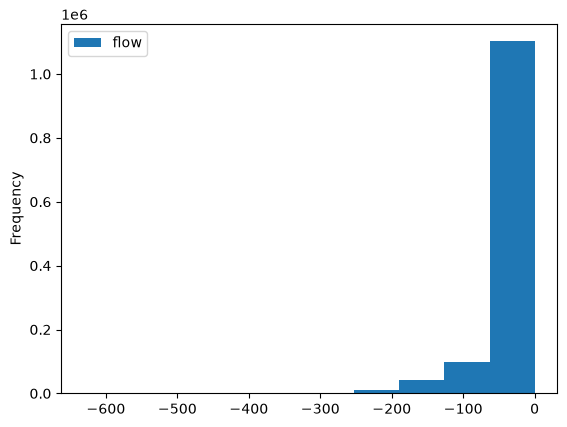

In [30]:
flow.iloc[:flow.shape[0]//2].plot(kind='hist')

<Axes: ylabel='Frequency'>

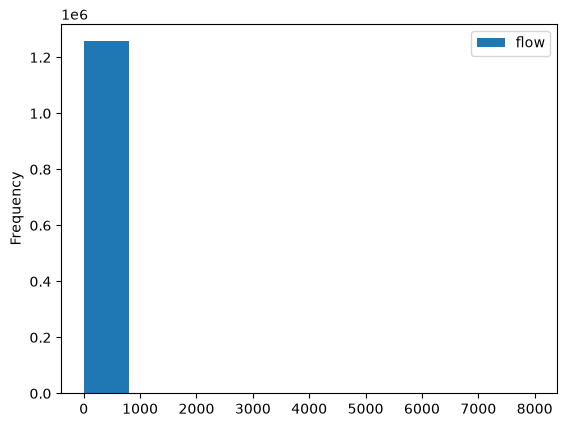

In [31]:
flow.iloc[flow.shape[0]//2:].plot(kind='hist')

In [32]:
flow.shape

(2513836, 2)

In [33]:
flow.duplicated(subset=['timestamp']).sum() #no duplicates in timestamp

np.int64(1257038)

In [34]:
# looks like all counts in one direction are listed ordered by timestamp
# then all counts in the other direction are listed ordered by timestamp
# split the flow into two sets
departures = flow.iloc[:flow.shape[0]//2].copy()
print(departures.shape)
arrivals = flow.iloc[flow.shape[0]//2:].copy()
print(arrivals.shape)

(1256918, 2)
(1256918, 2)


### Comparing departures and arrivals
Look at summary statistics for each half to sanity-check the split, then check for duplicate timestamps within each group and investigate when those duplicates occur.

In [35]:
departures.describe()

,timestamp,flow
count,1256918,1.256918e+06
mean,2018-03-18 15:57:52.410674,-2.153213e+01
min,2017-01-01 14:15:00,-6.310000e+02
25%,2017-08-13 06:00:15,-2.400000e+01
50%,2018-03-19 10:16:30,0.000000e+00
75%,2018-10-24 07:26:45,0.000000e+00
max,2019-05-31 14:15:00,0.000000e+00
std,NaN,4.229649e+01


In [36]:
departures.sort_values(by='timestamp')

,timestamp,flow
0,2017-01-01 14:15:00,0
1,2017-01-01 14:16:00,0
2,2017-01-01 14:17:00,0
3,2017-01-01 14:18:00,0
4,2017-01-01 14:19:00,0
...,...,...
1256913,2019-05-31 14:11:00,-241
1256914,2019-05-31 14:12:00,-226
1256915,2019-05-31 14:13:00,-208
1256916,2019-05-31 14:14:00,-217


In [37]:
arrivals.describe()

,timestamp,flow
count,1256918,1.256918e+06
mean,2018-03-18 15:57:52.410674,2.478130e+01
min,2017-01-01 14:15:00,0.000000e+00
25%,2017-08-13 06:00:15,0.000000e+00
50%,2018-03-19 10:16:30,0.000000e+00
75%,2018-10-24 07:26:45,2.400000e+01
max,2019-05-31 14:15:00,7.999000e+03
std,NaN,5.514607e+01


In [38]:
arrivals.sort_values(by='timestamp')

,timestamp,flow
1256918,2017-01-01 14:15:00,0
1256919,2017-01-01 14:16:00,0
1256920,2017-01-01 14:17:00,0
1256921,2017-01-01 14:18:00,0
1256922,2017-01-01 14:19:00,0
...,...,...
2513831,2019-05-31 14:11:00,128
2513832,2019-05-31 14:12:00,140
2513833,2019-05-31 14:13:00,144
2513834,2019-05-31 14:14:00,146


In [39]:
departures.duplicated().sum() # are all timestamps unique? no

np.int64(114)

In [40]:
arrivals.duplicated().sum() # are all timestamps unique? no

np.int64(120)

In [41]:
departures.loc[departures.duplicated()]

,timestamp,flow
424925,2017-10-29 02:00:00,0
424926,2017-10-29 02:01:00,0
424927,2017-10-29 02:02:00,0
424928,2017-10-29 02:03:00,0
424929,2017-10-29 02:04:00,0
...,...,...
948236,2018-10-28 02:55:00,0
948237,2018-10-28 02:56:00,0
948238,2018-10-28 02:57:00,0
948239,2018-10-28 02:58:00,0


In [42]:
departures.loc[
    departures.duplicated(subset=["timestamp"], keep=False)
].sort_values("timestamp")

,timestamp,flow
424865,2017-10-29 02:00:00,0
424925,2017-10-29 02:00:00,0
424866,2017-10-29 02:01:00,0
424926,2017-10-29 02:01:00,0
424867,2017-10-29 02:02:00,0
...,...,...
948178,2018-10-28 02:57:00,0
948239,2018-10-28 02:58:00,0
948179,2018-10-28 02:58:00,0
948180,2018-10-28 02:59:00,0


In [43]:
departures.loc[departures.duplicated(), 'timestamp'].dt.date.unique()

array([datetime.date(2017, 10, 29), datetime.date(2018, 10, 28)],
      dtype=object)

In [44]:
departures.loc[departures.duplicated(), 'timestamp'].dt.day_name().unique()

<ArrowStringArray>
['Sunday']
Length: 1, dtype: str

In [45]:
# fulfills all expectations of time change
departures.loc[departures.duplicated(), 'timestamp'].dt.hour.unique()

array([2], dtype=int32)

### Localizing and converting timestamps to UTC
The duplicate timestamps line up with the autumn daylight-saving clock change (the same local time occurs twice). Localize the timestamps to the `Europe/Berlin` timezone (resolving the ambiguous hour) and then convert to UTC so each instant is represented once, unambiguously.

In [46]:
departures['timestamp'].dt.tz_localize('Europe/Berlin', ambiguous='infer')

0         2017-01-01 14:15:00+01:00
1         2017-01-01 14:16:00+01:00
2         2017-01-01 14:17:00+01:00
3         2017-01-01 14:18:00+01:00
4         2017-01-01 14:19:00+01:00
                     ...           
1256913   2019-05-31 14:11:00+02:00
1256914   2019-05-31 14:12:00+02:00
1256915   2019-05-31 14:13:00+02:00
1256916   2019-05-31 14:14:00+02:00
1256917   2019-05-31 14:15:00+02:00
Name: timestamp, Length: 1256918, dtype: datetime64[us, Europe/Berlin]

In [47]:
departures['timestamp'].dt.tz_localize('Europe/Berlin', ambiguous='infer')
departures.duplicated().sum()

np.int64(114)

In [48]:
df3 = departures.copy()
df3['timestamp'] = df3['timestamp'].dt.tz_localize('Europe/Berlin', ambiguous='infer')
df3.duplicated().sum()

np.int64(0)

In [49]:
df3['timestamp']= df3['timestamp'].dt.tz_convert('UTC')
df3['timestamp']

0         2017-01-01 13:15:00+00:00
1         2017-01-01 13:16:00+00:00
2         2017-01-01 13:17:00+00:00
3         2017-01-01 13:18:00+00:00
4         2017-01-01 13:19:00+00:00
                     ...           
1256913   2019-05-31 12:11:00+00:00
1256914   2019-05-31 12:12:00+00:00
1256915   2019-05-31 12:13:00+00:00
1256916   2019-05-31 12:14:00+00:00
1256917   2019-05-31 12:15:00+00:00
Name: timestamp, Length: 1256918, dtype: datetime64[us, UTC]

In [50]:
# because local time changes with season, convert to UTC
departures['timestamp'] = departures['timestamp'].dt.tz_localize('Europe/Berlin', ambiguous='infer').dt.tz_convert('UTC')

In [51]:
# because local time changes with season, convert to UTC
arrivals['timestamp'] = arrivals['timestamp'].dt.tz_localize('Europe/Berlin', ambiguous='infer').dt.tz_convert('UTC')

In [52]:
departures.duplicated().sum(),arrivals.duplicated().sum() # no more duplicates

(np.int64(0), np.int64(0))

### Checking the value distribution for outliers
Plot a histogram of the flow values (log scale, since a few values are far larger than the rest) and inspect the largest values and their timestamps to judge whether they look like measurement errors.

<Axes: >

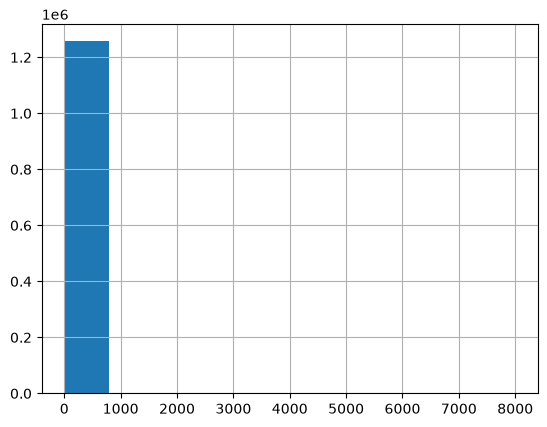

In [53]:
arrivals['flow'].hist()

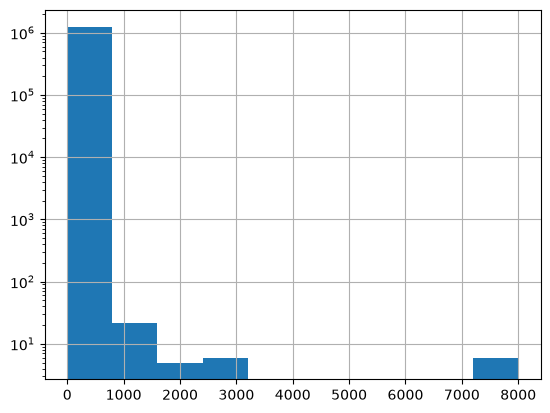

In [54]:
# what's the distribution of counts?
flow_hist = arrivals['flow'].hist()
flow_hist.set_yscale('log') # some numbers seem like outliers

In [55]:
arrivals['flow'].nlargest(10) # 7999 is a pretty big gap from the rest of the figures

2084055    7999
2098359    7999
2107004    7999
2107005    7999
2107009    7999
2107010    7999
2107023    3148
2101589    3042
1531827    2755
2091430    2629
Name: flow, dtype: int64

In [56]:
arrivals.describe()

,flow
count,1.256918e+06
mean,2.478130e+01
std,5.514607e+01
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,2.400000e+01
max,7.999000e+03


In [57]:
IQR = 24 - 0
1.5 * IQR

36.0

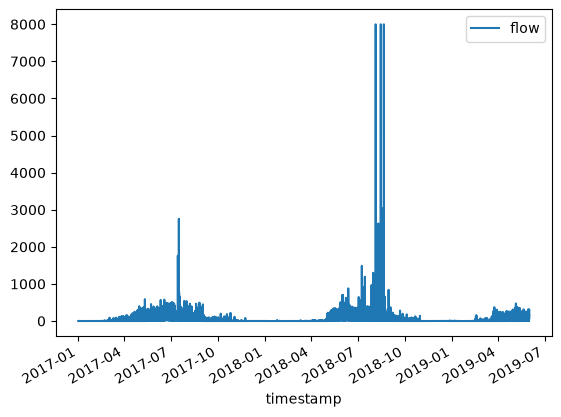

In [58]:
# all the highest values cluster in a few days. measurement error?
# you can decide if these are outliers worth excluding or the future analyst's problem
arrivals.plot(kind='line',x='timestamp', y='flow');

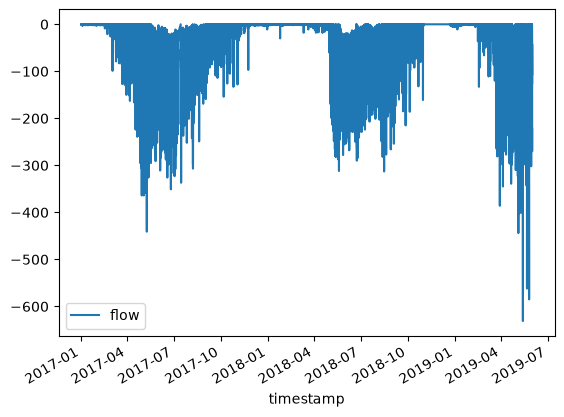

In [59]:
departures.plot(kind='line',x='timestamp', y='flow');


In [60]:
arrivals.loc[arrivals['flow'].between(3000,7999)]

,timestamp,flow
2084055,2018-08-04 23:25:00+00:00,7999
2098359,2018-08-14 21:50:00+00:00,7999
2101589,2018-08-17 03:41:00+00:00,3042
2107004,2018-08-20 21:56:00+00:00,7999
2107005,2018-08-20 21:57:00+00:00,7999
2107009,2018-08-20 22:01:00+00:00,7999
2107010,2018-08-20 22:02:00+00:00,7999
2107023,2018-08-20 22:15:00+00:00,3148


## Reassembly and regularity

Merge the cleaned `departures` and `arrivals` back into a single flow DataFrame keyed on `timestamp`, then check that timestamps are regular and free of duplicates.

In [61]:
# merge flow figures back into one dataframe
flow_cl = departures.merge(arrivals, on='timestamp', suffixes=('_out', '_in'))

In [62]:
flow_cl.head()

,timestamp,flow_out,flow_in
0,2017-01-01 13:15:00+00:00,0,0
1,2017-01-01 13:16:00+00:00,0,0
2,2017-01-01 13:17:00+00:00,0,0
3,2017-01-01 13:18:00+00:00,0,0
4,2017-01-01 13:19:00+00:00,0,0


In [63]:
# timestamps still aren't perfectly regular
(flow_cl['timestamp'] - flow_cl['timestamp'].shift(1)).value_counts()

#shift(1) moves all values down by one row.
#so each row can be compared to the previous timestamp.

timestamp
0 days 00:01:00    1256857
0 days 00:02:00         56
5 days 09:32:00          1
0 days 11:56:00          1
0 days 02:44:00          1
1 days 01:19:00          1
Name: count, dtype: int64

In [64]:
flow_cl.loc[(flow_cl['timestamp'] - flow_cl['timestamp'].shift(1)) == '5 days 09:32:00']

,timestamp,flow_out,flow_in
271556,2017-07-14 12:46:00+00:00,0,0


In [65]:
flow_cl.loc[271550:271560]

,timestamp,flow_out,flow_in
271550,2017-07-09 03:09:00+00:00,-21,24
271551,2017-07-09 03:10:00+00:00,-20,20
271552,2017-07-09 03:11:00+00:00,-14,17
271553,2017-07-09 03:12:00+00:00,-21,20
271554,2017-07-09 03:13:00+00:00,-23,23
271555,2017-07-09 03:14:00+00:00,-21,13
271556,2017-07-14 12:46:00+00:00,0,0
271557,2017-07-14 12:47:00+00:00,-153,162
271558,2017-07-14 12:48:00+00:00,-167,213
271559,2017-07-14 12:49:00+00:00,-141,191


<Axes: xlabel='timestamp'>

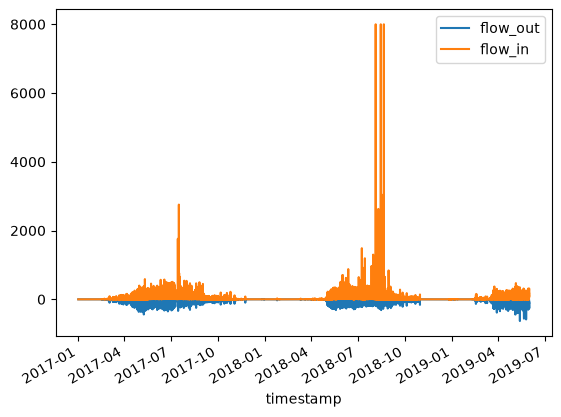

In [66]:
flow_cl.set_index('timestamp', inplace=True)
flow_cl.plot()

In [67]:
flow_cl.duplicated().sum()

np.int64(1212268)

In [68]:
flow_cl

,flow_out,flow_in
timestamp,,
2017-01-01 13:15:00+00:00,0,0
2017-01-01 13:16:00+00:00,0,0
2017-01-01 13:17:00+00:00,0,0
2017-01-01 13:18:00+00:00,0,0
2017-01-01 13:19:00+00:00,0,0
...,...,...
2019-05-31 12:11:00+00:00,-241,128
2019-05-31 12:12:00+00:00,-226,140
2019-05-31 12:13:00+00:00,-208,144


In [98]:
flow_cl.head()

,flow_out,flow_in
timestamp,,
2017-01-01 13:15:00+00:00,0,0
2017-01-01 13:16:00+00:00,0,0
2017-01-01 13:17:00+00:00,0,0
2017-01-01 13:18:00+00:00,0,0
2017-01-01 13:19:00+00:00,0,0


In [99]:
print(flow.columns.tolist())

['timestamp', 'flow']


# Humidity

### Initial inspection
Check structure and missing values, then preview the data — humidity is recorded every 12 hours here.

In [69]:
humidity.info() #transform timestamp Dtype & deal with missing values

<class 'pandas.DataFrame'>
RangeIndex: 1761 entries, 0 to 1760
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  1761 non-null   datetime64[us]
 1   humidity   1749 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 27.6 KB


<Axes: title={'center': 'Humidity distribution'}, ylabel='Frequency'>

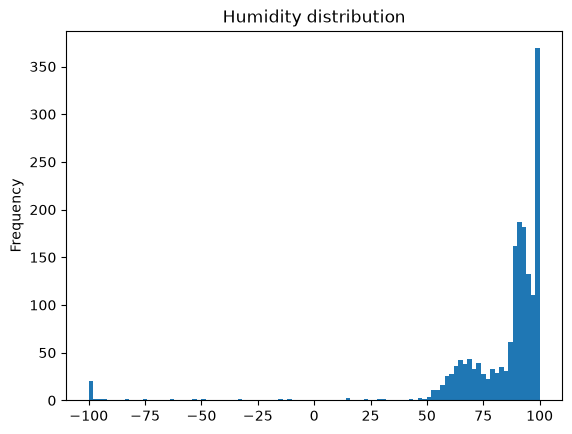

In [70]:
humidity.humidity.plot(kind='hist', bins=100, title='Humidity distribution')

In [71]:
humidity.head(10) #the gap between the recordings is 12 hours

,timestamp,humidity
0,2017-01-01 13:00:00,98.04
1,2017-01-02 01:00:00,98.61
2,2017-01-02 13:00:00,99.00
3,2017-01-03 01:00:00,98.49
4,2017-01-03 13:00:00,98.32
5,2017-01-04 01:00:00,97.41
6,2017-01-04 13:00:00,97.17
7,2017-01-05 01:00:00,97.12
8,2017-01-05 13:00:00,96.05
9,2017-01-06 01:00:00,96.12


### Checking for invalid values
Humidity should never be negative, so look for negative readings and test whether simply taking the absolute value produces a plausible-looking series.

In [72]:
humidity.describe() # humidity should not be negative

,timestamp,humidity
count,1761,1749.000000
mean,2018-03-17 13:33:45.894378,83.987816
min,2017-01-01 13:00:00,-100.000000
25%,2017-08-09 14:00:00,79.330000
50%,2018-03-17 13:00:00,91.070000
75%,2018-10-23 14:00:00,96.610000
max,2019-05-31 14:00:00,100.000000
std,NaN,26.501959


In [73]:
humidity.loc[humidity['humidity']<0]

,timestamp,humidity
51,2017-01-27 01:00:00,-100.00
52,2017-01-27 13:00:00,-82.25
65,2017-02-03 01:00:00,-100.00
66,2017-02-03 13:00:00,-100.00
67,2017-02-04 01:00:00,-100.00
68,2017-02-04 13:00:00,-100.00
69,2017-02-05 01:00:00,-100.00
70,2017-02-05 13:00:00,-100.00
71,2017-02-06 01:00:00,-100.00
72,2017-02-06 13:00:00,-100.00


<Axes: xlabel='timestamp'>

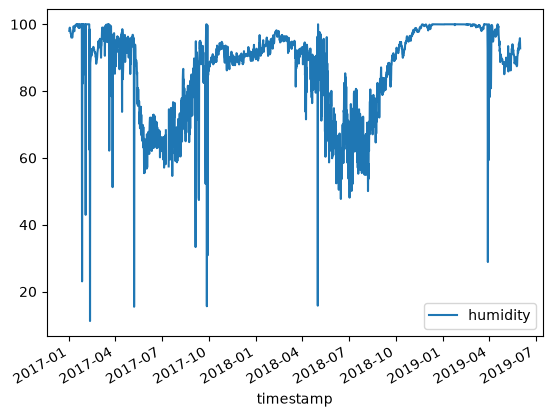

In [74]:
humidity2 = humidity.copy() # copy to see what happens when fixing values
humidity2['humidity'] = humidity2['humidity'].abs() # all positive values
humidity2.plot(kind='line', x='timestamp', y='humidity') # doesn't look unreasonable

In [75]:
humidity2.duplicated().sum() #no duplicates

np.int64(0)

### Checking timestamp regularity and the DST transition
Compute the gap between consecutive timestamps to confirm the 12-hour sampling interval, then zoom into the two autumn dates where the clock change would create an ambiguous, repeated local hour.

In [76]:
(humidity2['timestamp'] - humidity2['timestamp'].shift(1)).value_counts()

#shift(1) moves all values down by one row.
#so each row can be compared to the previous timestamp.

timestamp
0 days 12:00:00    1755
0 days 13:00:00       3
0 days 11:00:00       2
Name: count, dtype: int64

In [77]:
humidity2.loc[humidity2['timestamp'].dt.strftime('%Y-%m-%d') == '2017-10-29']

,timestamp,humidity
601,2017-10-29 02:00:00,93.11
602,2017-10-29 13:00:00,93.30


In [78]:
humidity2.loc[humidity2['timestamp'].dt.strftime('%Y-%m-%d') == '2018-10-28']

,timestamp,humidity
1329,2018-10-28 02:00:00,96.52
1330,2018-10-28 13:00:00,96.55


In [79]:
# investigate problem dates
humidity2.loc[humidity2['timestamp'].dt.strftime('%Y-%m-%d') == '2017-10-29'] # indexes 601:602
humidity2.loc[humidity2['timestamp'].dt.strftime('%Y-%m-%d') == '2018-10-28'] # indexes 1329:1330

# # zoom out a little to get the pattern of measurements
#humidity2.loc[598:604]
humidity2.loc[1326:1332]


# it seems all ambiguous dates (at 2am) are recorded BEFORE the clocks change

,timestamp,humidity
1326,2018-10-26 14:00:00,95.02
1327,2018-10-27 02:00:00,95.60
1328,2018-10-27 14:00:00,95.94
1329,2018-10-28 02:00:00,96.52
1330,2018-10-28 13:00:00,96.55
1331,2018-10-29 01:00:00,96.03
1332,2018-10-29 13:00:00,95.57


### Localizing and converting to UTC
Resolve the ambiguous DST hour by keeping the first occurrence, then convert to UTC. Re-check timestamp regularity afterward.

In [80]:
humidity2['timestamp'] = humidity2['timestamp'].dt.tz_localize(
    "Europe/Berlin",
    ambiguous=True  # True = first occurrence, False = second occurrence
).dt.tz_convert("UTC")


In [81]:
# timestamps are perfectly regular
(humidity2['timestamp'] - humidity2['timestamp'].shift(1)).value_counts()

timestamp
0 days 12:00:00    1760
Name: count, dtype: int64

### Missing values
Look at where humidity readings are null to see whether the gaps form a pattern (e.g. a multi-day outage at the site).

In [82]:
humidity2.loc[humidity2['humidity'].isnull()] # look at null values for pattern

# was there some problem at the site for several days? storm? sickness?

,timestamp,humidity
378,2017-07-09 12:00:00+00:00,NaN
379,2017-07-10 00:00:00+00:00,NaN
380,2017-07-10 12:00:00+00:00,NaN
381,2017-07-11 00:00:00+00:00,NaN
382,2017-07-11 12:00:00+00:00,NaN
383,2017-07-12 00:00:00+00:00,NaN
384,2017-07-12 12:00:00+00:00,NaN
385,2017-07-13 00:00:00+00:00,NaN
386,2017-07-13 12:00:00+00:00,NaN
387,2017-07-14 00:00:00+00:00,NaN


# Temperature

### Initial inspection and timezone conversion
Check structure and preview the data (5-minute sampling interval here), remove duplicates, and convert timestamps to UTC the same way as for the other sensors.

In [83]:
temperature.info() #transform timestamp Dtype & deal with missing values

<class 'pandas.DataFrame'>
RangeIndex: 253430 entries, 0 to 253429
Data columns (total 2 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   timestamp    253430 non-null  datetime64[us]
 1   temperature  251398 non-null  float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 3.9 MB


In [84]:
temperature.head(10) #the gap between the recordings is 5 min

,timestamp,temperature
0,2017-01-01 14:10:00,NaN
1,2017-01-01 14:15:00,12.34
2,2017-01-01 14:20:00,12.27
3,2017-01-01 14:25:00,12.28
4,2017-01-01 14:30:00,12.36
5,2017-01-01 14:35:00,12.40
6,2017-01-01 14:40:00,12.47
7,2017-01-01 14:45:00,12.49
8,2017-01-01 14:50:00,12.48
9,2017-01-01 14:55:00,12.50


In [85]:
temperature.duplicated().sum()

np.int64(0)

In [86]:
temperature[temperature.temperature.isna()]['timestamp']

0        2017-01-01 14:10:00
54313    2017-07-09 05:15:00
54314    2017-07-09 05:20:00
54315    2017-07-09 05:25:00
54316    2017-07-09 05:30:00
                 ...        
229661   2019-03-10 00:35:00
229662   2019-03-10 00:40:00
229663   2019-03-10 00:45:00
229664   2019-03-10 00:50:00
229665   2019-03-10 00:55:00
Name: timestamp, Length: 2032, dtype: datetime64[us]

In [87]:
print(temperature['timestamp'].dtype)
print(temperature['timestamp'].head())

datetime64[us]
0   2017-01-01 14:10:00
1   2017-01-01 14:15:00
2   2017-01-01 14:20:00
3   2017-01-01 14:25:00
4   2017-01-01 14:30:00
Name: timestamp, dtype: datetime64[us]


In [107]:
temperature["timestamp"] = temperature["timestamp"].dt.tz_localize("UTC")

### Checking values and missing data
The summary statistics look high at first glance but are normal for a sensor mounted inside a beehive. Check how much data is missing and whether the timestamps are already perfectly regular.

In [108]:
temperature.describe() # these temps seem high at first glance, but normal if measured inside the beehive

,temperature
count,251398.000000
mean,22.609671
std,11.702222
min,-7.260000
25%,12.450000
50%,24.480000
75%,34.220000
max,37.530000


In [ ]:
temperature.isna().sum()

timestamp         0
temperature    2032
dtype: int64

In [109]:
temperature.loc[temperature['temperature'].isna(), 'timestamp'].dt.date.unique()

array([datetime.date(2017, 1, 1), datetime.date(2017, 7, 9),
       datetime.date(2017, 7, 10), datetime.date(2017, 7, 11),
       datetime.date(2017, 7, 12), datetime.date(2017, 7, 13),
       datetime.date(2017, 7, 14), datetime.date(2018, 4, 28),
       datetime.date(2018, 5, 16), datetime.date(2019, 3, 8),
       datetime.date(2019, 3, 9), datetime.date(2019, 3, 10)],
      dtype=object)

In [110]:
temperature.loc[temperature['temperature'].isna(), 'timestamp'].dt.day_name()

0         Sunday
54313     Sunday
54314     Sunday
54315     Sunday
54316     Sunday
           ...  
229661    Sunday
229662    Sunday
229663    Sunday
229664    Sunday
229665    Sunday
Name: timestamp, Length: 2032, dtype: str

In [111]:
# where is data missing? several whole days clustered together (one whole day by itself), and scattered at other times
temperature.loc[temperature['temperature'].isna(), 'timestamp'].dt.date.value_counts()

timestamp
2017-07-10    288
2017-07-11    288
2017-07-12    288
2017-07-13    288
2019-03-09    288
2017-07-09    225
2017-07-14    177
2018-04-28    142
2018-05-16     32
2019-03-10     12
2019-03-08      3
2017-01-01      1
Name: count, dtype: int64

In [112]:
(temperature['timestamp'] - temperature['timestamp'].shift(1)).value_counts()
# already perfectly regular

timestamp
0 days 00:05:00      253424
0 days 01:05:00           3
-1 days +23:05:00         2
Name: count, dtype: int64

# Weight

### Initial inspection and timezone conversion
Check structure, preview the data (12-hour sampling interval), and localize/convert timestamps to UTC as with the other sensors.

In [89]:
weight.info() #transform timestamp Dtype & deal with missing values

<class 'pandas.DataFrame'>
RangeIndex: 1761 entries, 0 to 1760
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  1761 non-null   datetime64[us]
 1   weight     1749 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 27.6 KB


In [90]:
weight.head(10) #the gap between the recordings is 12 hours

,timestamp,weight
0,2017-01-01 13:00:00,50736.79
1,2017-01-02 01:00:00,50700.68
2,2017-01-02 13:00:00,50614.91
3,2017-01-03 01:00:00,50739.82
4,2017-01-03 13:00:00,50799.75
5,2017-01-04 01:00:00,50650.27
6,2017-01-04 13:00:00,50414.94
7,2017-01-05 01:00:00,50167.52
8,2017-01-05 13:00:00,50052.09
9,2017-01-06 01:00:00,49881.48


In [91]:
weight.describe() # cannot have negative weight

,timestamp,weight
count,1761,1749.000000
mean,2018-03-17 13:33:45.894378,56807.637313
min,2017-01-01 13:00:00,-172.440000
25%,2017-08-09 14:00:00,49793.360000
50%,2018-03-17 13:00:00,58029.270000
75%,2018-10-23 14:00:00,67322.570000
max,2019-05-31 14:00:00,92042.230000
std,NaN,16926.937629


In [92]:
# same logic applies as with humidity
weight['timestamp'] = weight['timestamp'].dt.tz_localize(
    "Europe/Berlin",
    ambiguous=True  # True = first occurrence, False = second occurrence
).dt.tz_convert("UTC")

### Checking for invalid values
Weight can't be negative, so inspect any negative readings, plot the series, and test whether taking the absolute value gives a reasonable result before applying the fix.

In [93]:
weight.loc[weight['weight'] < 0] # investigate negative weights

,timestamp,weight
964,2018-04-28 12:00:00+00:00,-170.61
965,2018-04-29 00:00:00+00:00,-172.44
966,2018-04-29 12:00:00+00:00,-167.10
1001,2018-05-17 00:00:00+00:00,-101.54
1061,2018-06-16 00:00:00+00:00,-157.49
1062,2018-06-16 12:00:00+00:00,-143.38
1063,2018-06-17 00:00:00+00:00,-157.63
1064,2018-06-17 12:00:00+00:00,-149.62
1065,2018-06-18 00:00:00+00:00,-162.12
1066,2018-06-18 12:00:00+00:00,-147.43


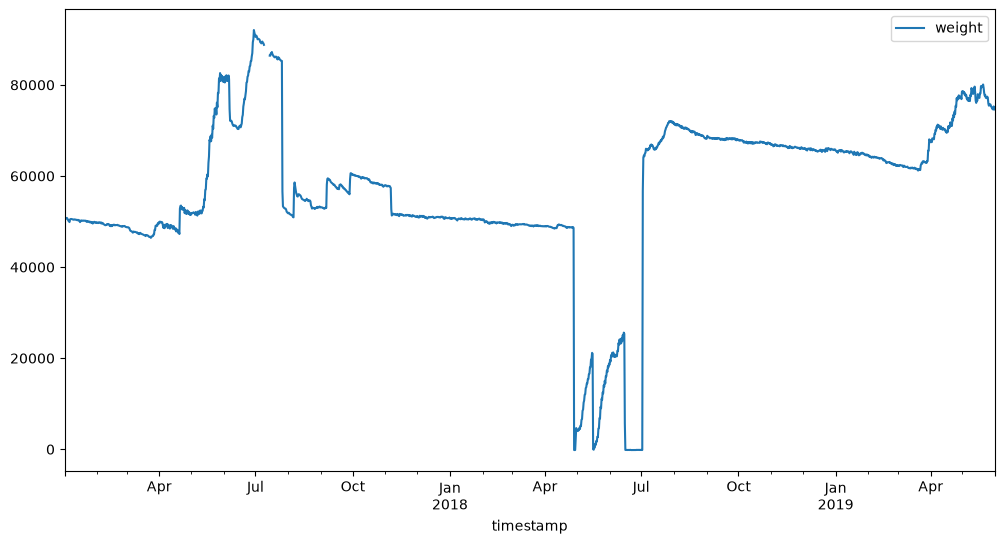

In [94]:
# plot them to look for pattern
# they're really not even visible
weight.plot(kind='line', x='timestamp', y='weight', figsize=(12, 6));

<Axes: xlabel='timestamp'>

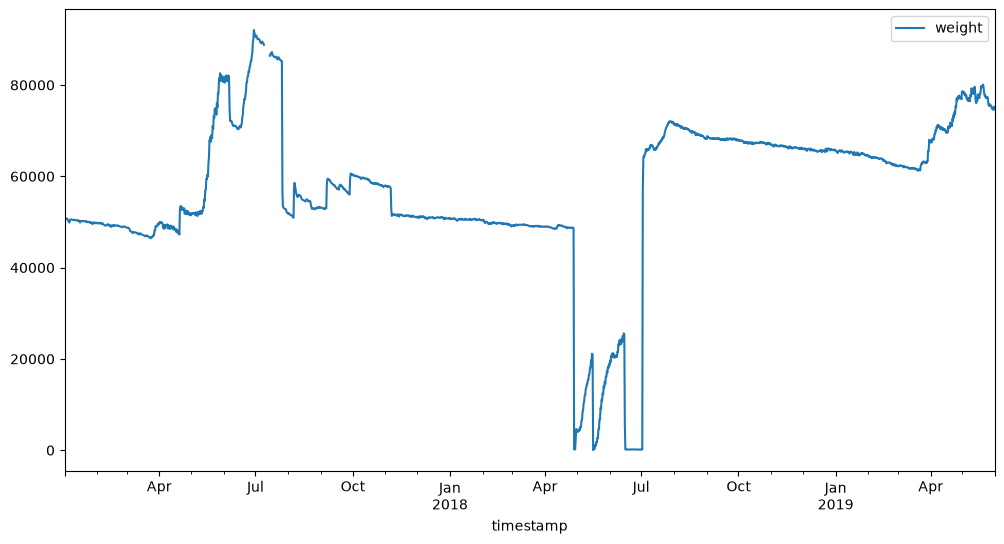

In [95]:
# test out making negatives positive
# There is 0 or very close to 0 weight. What that means?
weight2 = weight.copy()
weight2['weight'] = weight2['weight'].abs()
weight2.plot(kind='line', x='timestamp', y='weight', figsize=(12, 6))

In [96]:
weight['weight'] = weight['weight'].abs()

### Final regularity check
Confirm the cleaned weight timestamps are evenly spaced.

In [97]:
(weight['timestamp'] - weight['timestamp'].shift(1)).value_counts()
# already perfectly regular

timestamp
0 days 12:00:00    1760
Name: count, dtype: int64

# Data writes

### Saving the cleaned data
Write each cleaned dataset out to the silver layer as a timestamped Parquet file.

In [ ]:
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path

silver_path = Path("resource/silver")

# Create Silver and its subfolders
for folder in ["flow", "humidity", "temperature", "weight"]:
    (silver_path / folder).mkdir(parents=True, exist_ok=True)

In [ ]:
import pandas as pd
import pyarrow as pa

print("Pandas version:", pd.__version__)
print("PyArrow version:", pa.__version__)

Pandas version: 3.0.6
PyArrow version: 26.0.0


In [ ]:
%pip install --upgrade pandas pyarrow

Note: you may need to restart the kernel to use updated packages.


In [101]:
print(flow_cl.columns.tolist())
print(flow_cl.head())

['flow_out', 'flow_in']
                           flow_out  flow_in
timestamp                                   
2017-01-01 13:15:00+00:00         0        0
2017-01-01 13:16:00+00:00         0        0
2017-01-01 13:17:00+00:00         0        0
2017-01-01 13:18:00+00:00         0        0
2017-01-01 13:19:00+00:00         0        0


In [102]:
flow_cl = flow_cl.reset_index()

In [103]:
print(flow_cl.columns.tolist())
print(flow_cl.head())

['timestamp', 'flow_out', 'flow_in']
                  timestamp  flow_out  flow_in
0 2017-01-01 13:15:00+00:00         0        0
1 2017-01-01 13:16:00+00:00         0        0
2 2017-01-01 13:17:00+00:00         0        0
3 2017-01-01 13:18:00+00:00         0        0
4 2017-01-01 13:19:00+00:00         0        0


In [100]:
print("Columns in flow_cl:", flow_cl.columns.tolist())
print(flow_cl.head())
print("Index:", flow_cl.index)

Columns in flow_cl: ['flow_out', 'flow_in']
                           flow_out  flow_in
timestamp                                   
2017-01-01 13:15:00+00:00         0        0
2017-01-01 13:16:00+00:00         0        0
2017-01-01 13:17:00+00:00         0        0
2017-01-01 13:18:00+00:00         0        0
2017-01-01 13:19:00+00:00         0        0
Index: DatetimeIndex(['2017-01-01 13:15:00+00:00', '2017-01-01 13:16:00+00:00',
               '2017-01-01 13:17:00+00:00', '2017-01-01 13:18:00+00:00',
               '2017-01-01 13:19:00+00:00', '2017-01-01 13:20:00+00:00',
               '2017-01-01 13:21:00+00:00', '2017-01-01 13:22:00+00:00',
               '2017-01-01 13:23:00+00:00', '2017-01-01 13:24:00+00:00',
               ...
               '2019-05-31 12:06:00+00:00', '2019-05-31 12:07:00+00:00',
               '2019-05-31 12:08:00+00:00', '2019-05-31 12:09:00+00:00',
               '2019-05-31 12:10:00+00:00', '2019-05-31 12:11:00+00:00',
               '2019-05-31 12:1

In [113]:
import pandas as pd
from pathlib import Path

silver_path = Path("resource/silver")

# Generate a timestamp for the filenames
timestamp = pd.Timestamp.now().strftime("%Y-%m-%dT%Hh%Mm%Ss")

# Save each DataFrame
flow_cl.to_parquet(
    silver_path / "flow" / f"schwartau__{timestamp}.parquet",
    engine="pyarrow",
    index=False
)

humidity2.to_parquet(
    silver_path / "humidity" / f"schwartau__{timestamp}.parquet",
    engine="pyarrow",
    index=False
)

temperature.to_parquet(
    silver_path / "temperature" / f"schwartau__{timestamp}.parquet",
    engine="pyarrow",
    index=False
)

weight.to_parquet(
    silver_path / "weight" / f"schwartau__{timestamp}.parquet",
    engine="pyarrow",
    index=False
)

print("All DataFrames saved successfully!")

All DataFrames saved successfully!
